# 02 — Baseline ANN Training

This notebook trains a baseline Artificial Neural Network (ANN) to classify Arabic customer reviews as negative, neutral, or positive. It uses the processed files created by Notebook 01.

The workflow follows the ANN training cycle from Lab 2: forward propagation, loss calculation, backpropagation, and parameter updates. The notebook also plots training and validation accuracy and loss.

This is a baseline model. It uses the original class distribution and does not apply regularization or early stopping; those improvements will be investigated in Notebook 03.

## 1. Requirements

Run this notebook with the same Python environment used by Jupyter. If TensorFlow is not installed, install it from the terminal in the active virtual environment:

`python -m pip install tensorflow`

For operating-system-specific installation instructions, including GPU support, consult the [official TensorFlow installation guide](https://www.tensorflow.org/install/pip).

In [1]:
# Run this command in the terminal only if TensorFlow is not installed.
# %pip install tensorflow

In [2]:
from IPython.display import display
from pathlib import Path
import json
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import load_npz
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
BATCH_SIZE = 256
EPOCHS = 10
NUM_CLASSES = 3
LABEL_NAMES = ["Negative", "Neutral", "Positive"]

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

cwd = Path.cwd().resolve()
project_candidates = [cwd, *cwd.parents]
project_dir = next(
    (
        path for path in project_candidates
        if (path / "data" / "processed" / "X_train.npz").exists()
    ),
    None,
)

if project_dir is None:
    raise FileNotFoundError(
        "Could not find data/processed/X_train.npz. "
        "Run Notebook 01 first and open this notebook from the project folder."
    )

processed_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"
results_dir = project_dir / "results"
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_dir)
print("Processed data folder:", processed_dir)
print("Model output folder:", models_dir)
print("Results folder:", results_dir)

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Project folder: E:\ANN\ANN_01
Processed data folder: E:\ANN\ANN_01\data\processed
Model output folder: E:\ANN\ANN_01\models
Results folder: E:\ANN\ANN_01\results


## 2. Load the Processed Data

The text features are stored as sparse matrices to reduce disk and memory usage. They will be converted to dense arrays one mini-batch at a time during training.

In [3]:
train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")

X_train = load_npz(processed_dir / "X_train.npz").tocsr()
X_validation = load_npz(processed_dir / "X_validation.npz").tocsr()

y_train = train_df["label"].to_numpy(dtype=np.int64)
y_validation = validation_df["label"].to_numpy(dtype=np.int64)

if X_train.shape[0] != len(y_train):
    raise ValueError("The number of training feature rows does not match the training labels.")
if X_validation.shape[0] != len(y_validation):
    raise ValueError("The number of validation feature rows does not match the validation labels.")
if X_train.shape[1] != X_validation.shape[1]:
    raise ValueError("Training and validation feature dimensions do not match.")
if not np.isin(y_train, np.arange(NUM_CLASSES)).all():
    raise ValueError("Training labels must be encoded as 0, 1, and 2.")
if not np.isin(y_validation, np.arange(NUM_CLASSES)).all():
    raise ValueError("Validation labels must be encoded as 0, 1, and 2.")

INPUT_DIM = X_train.shape[1]

print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_validation.shape)
print("Input features:", INPUT_DIM)
print("Training samples:", f"{len(y_train):,}")
print("Validation samples:", f"{len(y_validation):,}")

print("Training class distribution:")
display(
    train_df["label"]
    .map(dict(enumerate(LABEL_NAMES)))
    .value_counts()
    .reindex(LABEL_NAMES, fill_value=0)
    .to_frame("count")
)

Training feature matrix: (319582, 8000)
Validation feature matrix: (39948, 8000)
Input features: 8000
Training samples: 319,582
Validation samples: 39,948
Training class distribution:


,count
label,
Negative,41690
Neutral,63551
Positive,214341


## 3. Prepare Mini-Batches

Each sparse matrix slice is converted to a dense mini-batch immediately before it is passed to the ANN. This avoids creating a dense copy of the entire dataset in memory.

In [4]:
def make_dataset(features, labels, batch_size, shuffle=False):
    labels = np.asarray(labels, dtype=np.int64)
    number_of_samples = features.shape[0]
    epoch_counter = {"value": 0}

    def batch_generator():
        if shuffle:
            rng = np.random.default_rng(SEED + epoch_counter["value"])
            indices = rng.permutation(number_of_samples)
            epoch_counter["value"] += 1
        else:
            indices = np.arange(number_of_samples)

        for start in range(0, number_of_samples, batch_size):
            batch_indices = indices[start:start + batch_size]
            batch_features = features[batch_indices].toarray().astype(np.float32, copy=False)
            batch_labels = labels[batch_indices]
            yield batch_features, batch_labels

    dataset = tf.data.Dataset.from_generator(
        batch_generator,
        output_signature=(
            tf.TensorSpec(shape=(None, features.shape[1]), dtype=tf.float32),
            tf.TensorSpec(shape=(None,), dtype=tf.int64),
        ),
    )

    # Prefetch one batch to limit additional memory use.
    return dataset.repeat().prefetch(1)

train_dataset = make_dataset(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
)
validation_dataset = make_dataset(
    X_validation,
    y_validation,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

train_steps = math.ceil(X_train.shape[0] / BATCH_SIZE)
validation_steps = math.ceil(X_validation.shape[0] / BATCH_SIZE)

print("Batch size:", BATCH_SIZE)
print("Training steps per epoch:", train_steps)
print("Validation steps:", validation_steps)

Batch size: 256
Training steps per epoch: 1249
Validation steps: 157


## 4. Build the Baseline ANN

The network uses two fully connected hidden layers with ReLU activation and a three-neuron Softmax output layer. The output size matches the three review classes.

In [5]:
model = keras.Sequential(
    [
        keras.Input(shape=(INPUT_DIM,), name="bag_of_words_features"),
        layers.Dense(128, activation="relu", name="hidden_1"),
        layers.Dense(64, activation="relu", name="hidden_2"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities"),
    ],
    name="baseline_ann",
)

model.summary()

Model: "baseline_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │     1,024,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,032,579 (3.94 MB)

 Trainable params: 1,032,579 (3.94 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Compile the Model

Sparse categorical cross-entropy is used because the class labels are integer encoded. Accuracy is recorded as a metric; the loss is the quantity optimized during training.

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("Optimizer: Adam")
print("Loss: Sparse Categorical Cross-Entropy")
print("Metric: Accuracy")

Optimizer: Adam
Loss: Sparse Categorical Cross-Entropy
Metric: Accuracy


## 6. Train the Baseline ANN

For each mini-batch, Keras performs forward propagation, calculates the loss, computes gradients through backpropagation, and updates the model parameters. Validation data is used to monitor performance after each epoch.

In [7]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    steps_per_epoch=train_steps,
    validation_steps=validation_steps,
    verbose=1,
)

Epoch 1/10


e:\ANN\ANN_01\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1249/1249 ━━━━━━━━━━━━━━━━━━━━ 29s 22ms/step - accuracy: 0.8579 - loss: 0.3794 - val_accuracy: 0.8695 - val_loss: 0.3470
Epoch 2/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.8882 - loss: 0.2998 - val_accuracy: 0.8668 - val_loss: 0.3548
Epoch 3/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 28s 23ms/step - accuracy: 0.9167 - loss: 0.2345 - val_accuracy: 0.8598 - val_loss: 0.3988
Epoch 4/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.9460 - loss: 0.1599 - val_accuracy: 0.8513 - val_loss: 0.5091
Epoch 5/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 28s 23ms/step - accuracy: 0.9662 - loss: 0.1039 - val_accuracy: 0.8482 - val_loss: 0.6634
Epoch 6/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.9777 - loss: 0.0707 - val_accuracy: 0.8449 - val_loss: 0.8371
Epoch 7/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 27s 22ms/step - accuracy: 0.9834 - loss: 0.0523 - val_accuracy: 0.8441 - val_loss: 0.9922
Epoch 8/10
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.9870 - loss: 0.04

## 7. Plot Training and Validation Curves

The curves show whether accuracy improves and loss decreases across epochs. A widening gap between training and validation performance can indicate overfitting.

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.8579,0.3794,0.8695,0.3470
2,0.8882,0.2998,0.8668,0.3548
3,0.9167,0.2345,0.8598,0.3988
4,0.9460,0.1599,0.8513,0.5091
5,0.9662,0.1039,0.8482,0.6634
6,0.9777,0.0707,0.8449,0.8371
7,0.9834,0.0523,0.8441,0.9922
8,0.9870,0.0421,0.8394,1.1178
9,0.9890,0.0356,0.8398,1.2245


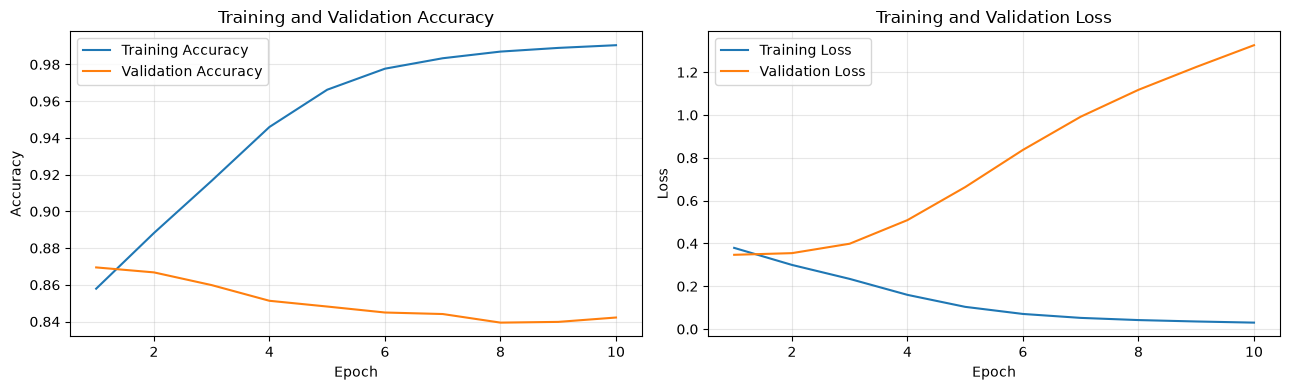

Learning curves saved to: E:\ANN\ANN_01\results\baseline_learning_curves.png


In [8]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "epoch"

display(history_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df.index, history_df["accuracy"], label="Training Accuracy")
axes[0].plot(history_df.index, history_df["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df.index, history_df["loss"], label="Training Loss")
axes[1].plot(history_df.index, history_df["val_loss"], label="Validation Loss")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
curve_path = results_dir / "baseline_learning_curves.png"
plt.savefig(curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Learning curves saved to:", curve_path)

## 8. Evaluate on the Validation Set

The test set is intentionally not loaded or evaluated in this baseline notebook. It will remain untouched until the final model evaluation in Notebook 03.

In [9]:
validation_loss, validation_accuracy = model.evaluate(
    validation_dataset,
    steps=validation_steps,
    verbose=1,
)

validation_metrics = {
    "validation_loss": float(validation_loss),
    "validation_accuracy": float(validation_accuracy),
    "epochs_completed": int(len(history_df)),
    "batch_size": BATCH_SIZE,
    "training_samples": int(X_train.shape[0]),
    "validation_samples": int(X_validation.shape[0]),
    "input_features": int(INPUT_DIM),
    "num_classes": NUM_CLASSES,
}

print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation accuracy: {validation_accuracy:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8422 - loss: 1.3262
Validation loss: 1.3262
Validation accuracy: 0.8422


## 9. Save the Baseline Model and Results

The model, training history, and validation metrics are saved for comparison in Notebook 03.

In [10]:
model_path = models_dir / "baseline_ann.keras"
history_path = results_dir / "baseline_training_history.csv"
metrics_path = results_dir / "baseline_validation_metrics.json"

model.save(model_path)
history_df.to_csv(history_path, encoding="utf-8")

with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(validation_metrics, file, indent=2)

print("Saved model:", model_path)
print("Saved training history:", history_path)
print("Saved validation metrics:", metrics_path)

Saved model: E:\ANN\ANN_01\models\baseline_ann.keras
Saved training history: E:\ANN\ANN_01\results\baseline_training_history.csv
Saved validation metrics: E:\ANN\ANN_01\results\baseline_validation_metrics.json


## Outputs

- `models/baseline_ann.keras`: the trained baseline ANN.
- `results/baseline_learning_curves.png`: training and validation accuracy and loss plots.
- `results/baseline_training_history.csv`: metric values recorded after each epoch.
- `results/baseline_validation_metrics.json`: final validation loss and accuracy.

The model uses the Bag-of-Words feature order created by Notebook 01. Keep `data/processed/count_vectorizer.joblib` with the saved model so new review text can be transformed in the same way.